# Détection de fraude Bitcoin par GNN

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, SAGEConv

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device :", device)

C:\Users\Busin\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


torch 2.14.0+cpu | device : cpu


### Options d'exécution
Les deux étapes longues sont mises en cache dans `cache/` :
- `TRAIN_GNN = False` recharge les GNN déjà entraînés (≈ 22 min économisées) ;
- `RUN_TUNING = False` recharge les résultats du tuning du Random Forest (≈ 15 min économisées).

Si le cache n'existe pas encore, l'étape est calculée quelle que soit l'option. Mettre à `True` pour forcer un recalcul.

In [2]:
from pathlib import Path

TRAIN_GNN = False
RUN_TUNING = False

CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)
GNN_CACHE = CACHE_DIR / "gnn_runs.pt"
TUNING_CACHE = CACHE_DIR / "rf_tuning.pkl"
print("GNN :", "entraînement" if TRAIN_GNN or not GNN_CACHE.exists() else "chargement du cache")
print("tuning RF :", "calcul" if RUN_TUNING or not TUNING_CACHE.exists() else "chargement du cache")

GNN : chargement du cache
tuning RF : chargement du cache


## 2. Chargement des datasets

In [3]:
# Features : pas d'en-tête -> txId, pas de temps, 94 features locales, 72 features agrégées
feature_cols = ["txId", "time_step"] + [f"local_{i}" for i in range(1, 94)] + [f"agg_{i}" for i in range(1, 73)]

df_features = pd.read_csv("elliptic_txs_features.csv", header=None, names=feature_cols)
df_classes = pd.read_csv("elliptic_txs_classes.csv")
df_edges = pd.read_csv("elliptic_txs_edgelist.csv")

print("features :", df_features.shape)
print("classes  :", df_classes.shape)
print("arêtes   :", df_edges.shape)

features : (203769, 167)
classes  : (203769, 2)
arêtes   : (234355, 2)


### Features

In [4]:
df_features.head()

,txId,time_step,local_1,local_2,local_3,local_4,local_5,local_6,local_7,local_8,...,agg_63,agg_64,agg_65,agg_66,agg_67,agg_68,agg_69,agg_70,agg_71,agg_72
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


### Classes
`1` = illicite, `2` = licite, `unknown` = non labellisé

In [5]:
df_classes.head()

,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown
3,232438397,2
4,230460314,unknown


In [6]:
counts = df_classes["class"].value_counts()
print(pd.DataFrame({"nombre": counts, "%": (counts / len(df_classes) * 100).round(1)}))

         nombre     %
class                
unknown  157205  77.1
2         42019  20.6
1          4545   2.2


### Arêtes (flux de BTC txId1 → txId2)

In [7]:
df_edges.head()

,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


## 3. Nettoyage

### 3.1 Valeurs manquantes et doublons

In [8]:
for name, d in [("features", df_features), ("classes", df_classes), ("arêtes", df_edges)]:
    print(f"{name:9s} | NaN : {d.isna().sum().sum():>6} | lignes dupliquées : {d.duplicated().sum():>6}")

print("\ntxId dupliqués (features) :", df_features["txId"].duplicated().sum())
print("txId dupliqués (classes)  :", df_classes["txId"].duplicated().sum())

features  | NaN :      0 | lignes dupliquées :      0
classes   | NaN :      0 | lignes dupliquées :      0
arêtes    | NaN :      0 | lignes dupliquées :      0

txId dupliqués (features) : 0
txId dupliqués (classes)  : 0


### 3.2 Cohérence entre les fichiers
Toutes les transactions des arêtes et des classes doivent exister dans les features.

In [9]:
ids = set(df_features["txId"])
print("classes absentes des features :", (~df_classes["txId"].isin(ids)).sum())
print("arêtes vers un txId inconnu   :", (~df_edges["txId1"].isin(ids) | ~df_edges["txId2"].isin(ids)).sum())
print("boucles (txId1 == txId2)      :", (df_edges["txId1"] == df_edges["txId2"]).sum())
print("arêtes en double              :", df_edges.duplicated().sum())

isolated = ids - set(df_edges["txId1"]) - set(df_edges["txId2"])
print("transactions isolées          :", len(isolated))

classes absentes des features : 0


arêtes vers un txId inconnu   : 0
boucles (txId1 == txId2)      : 0
arêtes en double              : 0


transactions isolées          : 0


### 3.3 Encodage des labels
`1` (illicite) → **1**, `2` (licite) → **0**, `unknown` → **-1** (gardé dans le graphe, exclu de l'entraînement).

In [10]:
label_map = {"1": 1, "2": 0, "unknown": -1}
df_classes["label"] = df_classes["class"].astype(str).map(label_map)
assert df_classes["label"].notna().all()

df = df_features.merge(df_classes[["txId", "label"]], on="txId", how="left").copy()
df["label_name"] = df["label"].map({1: "illicite", 0: "licite", -1: "inconnu"})
df["label_name"].value_counts()

label_name
inconnu     157205
licite       42019
illicite      4545
Name: count, dtype: int64

### 3.4 Features constantes ou redondantes
Aucune feature constante, mais plusieurs paires sont des copies à r ≈ 1 : on en retire une de chaque paire.

In [11]:
feat_cols = [c for c in df.columns if c.startswith(("local_", "agg_"))]

constant = [c for c in feat_cols if df[c].nunique() <= 1]
print("features constantes :", constant)

# colonnes strictement identiques à une autre
col_hash = pd.Series({c: hash(df[c].to_numpy().tobytes()) for c in feat_cols})
duplicated_cols = list(col_hash[col_hash.duplicated()].index)
print("features dupliquées :", duplicated_cols)

# paires très corrélées (|r| > 0.99) : signalées ; les quasi-copies (|r| > 0.9999) seront supprimées
corr = pd.DataFrame(np.abs(np.corrcoef(df[feat_cols].to_numpy(), rowvar=False)), index=feat_cols, columns=feat_cols)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_corr = upper.stack()[lambda s: s > 0.99].sort_values(ascending=False)
print(f"paires |r| > 0.99   : {len(high_corr)}")
high_corr.head(10)

features constantes : []


features dupliquées : []


paires |r| > 0.99   : 40


local_24  local_30    1.000000
local_23  local_29    1.000000
local_25  local_31    1.000000
local_22  local_28    1.000000
local_59  local_65    1.000000
local_61  local_67    1.000000
local_60  local_66    1.000000
local_58  local_64    0.999997
local_26  local_32    0.999589
local_27  local_33    0.999573
dtype: float64

In [12]:
# pour chaque paire quasi identique, on garde la première et on retire la seconde
near_copies = [b for (a, b), r in high_corr.items() if r > 0.9999]
print("quasi-copies supprimées :", sorted(set(near_copies)))

to_drop = sorted(set(constant) | set(duplicated_cols) | set(near_copies))
df = df.drop(columns=to_drop)
feat_cols = [c for c in feat_cols if c not in to_drop]
print(f"{len(to_drop)} features supprimées -> {len(feat_cols)} features restantes")

quasi-copies supprimées : ['local_28', 'local_29', 'local_30', 'local_31', 'local_64', 'local_65', 'local_66', 'local_67']
8 features supprimées -> 157 features restantes


### 3.5 Index des nœuds
PyTorch Geometric attend des nœuds numérotés de 0 à N-1 : on remplace les `txId` par un index.

In [13]:
df = df.reset_index(drop=True)
tx_to_idx = pd.Series(df.index, index=df["txId"])

edges = df_edges.drop_duplicates()
edges = edges[edges["txId1"] != edges["txId2"]]
edge_index = np.vstack([tx_to_idx[edges["txId1"]].values, tx_to_idx[edges["txId2"]].values])

labeled = df[df["label"] != -1]
print("nœuds :", len(df), "| arêtes :", edge_index.shape[1], "| nœuds labellisés :", len(labeled))

nœuds : 203769 | arêtes : 234355 | nœuds labellisés : 46564


## 4. Visualisations

In [14]:
# Style commun : marques fines, grille discrète, couleurs fixes par classe
COLORS = {"licite": "#2a78d6", "illicite": "#eb6834", "inconnu": "#b5b3ad"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # ordre fixe des modèles
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c7c1", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#e8e6e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})

### 4.1 Répartition des classes
Le déséquilibre est fort : seulement ~10 % des transactions labellisées sont illicites.

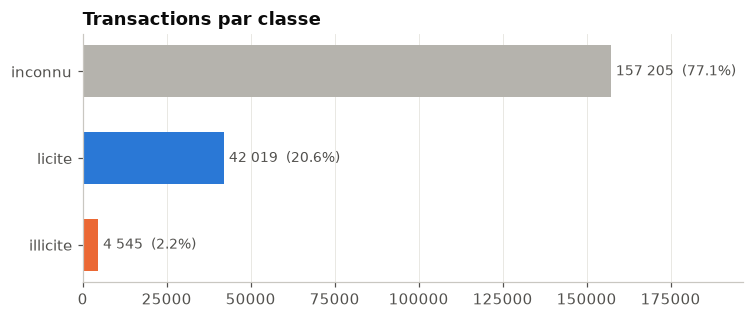

In [15]:
counts = df["label_name"].value_counts().reindex(["inconnu", "licite", "illicite"])
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(counts.index, counts.values, color=[COLORS[k] for k in counts.index], height=0.6)
for b, v in zip(bars, counts.values):
    ax.text(v + 1500, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / len(df):.1%})".replace(",", " "),
            va="center", color=INK2, fontsize=9)
ax.set_title("Transactions par classe")
ax.set_xlim(0, counts.max() * 1.25); ax.grid(axis="y", visible=False); ax.invert_yaxis()
plt.tight_layout(); plt.show()

### 4.2 Évolution dans le temps
Nombre de transactions labellisées et part d'illicites par pas de temps. La ligne pointillée marque le split train/test classique (pas 34). On voit l'effondrement des illicites après le pas 43 (fermeture d'un marché du darknet).

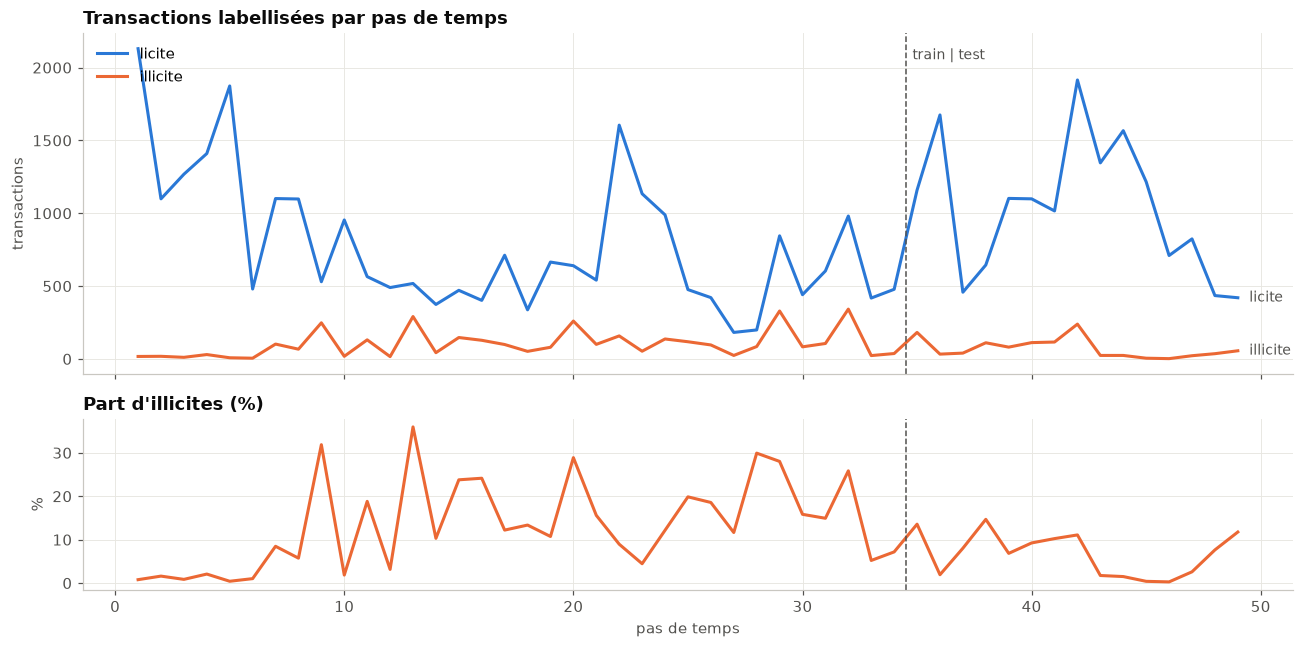

In [16]:
per_step = labeled.groupby(["time_step", "label_name"]).size().unstack(fill_value=0)
ratio = per_step["illicite"] / per_step.sum(axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for cls in ["licite", "illicite"]:
    ax1.plot(per_step.index, per_step[cls], color=COLORS[cls], label=cls)
    ax1.text(per_step.index[-1] + 0.5, per_step[cls].iloc[-1], cls, color=INK2, va="center", fontsize=9)
ax1.set_title("Transactions labellisées par pas de temps"); ax1.set_ylabel("transactions"); ax1.legend(loc="upper left")

ax2.plot(ratio.index, ratio.values * 100, color=COLORS["illicite"])
ax2.set_title("Part d'illicites (%)"); ax2.set_xlabel("pas de temps"); ax2.set_ylabel("%")
for ax in (ax1, ax2):
    ax.axvline(34.5, color=INK2, ls="--", lw=1)
ax1.text(34.8, ax1.get_ylim()[1] * 0.92, "train | test", color=INK2, fontsize=9)
plt.tight_layout(); plt.show()

### 4.3 Structure du graphe : distribution des degrés
La plupart des transactions ont 1 ou 2 voisins, quelques-unes en ont des centaines (échelle log-log).

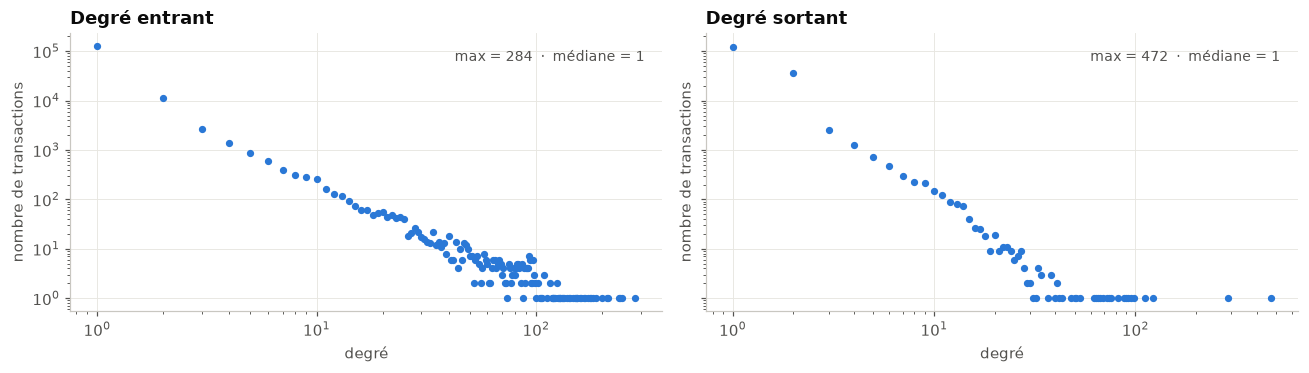

In [17]:
in_deg = np.bincount(edge_index[1], minlength=len(df))
out_deg = np.bincount(edge_index[0], minlength=len(df))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, deg, title in [(axes[0], in_deg, "Degré entrant"), (axes[1], out_deg, "Degré sortant")]:
    vals, cnt = np.unique(deg[deg > 0], return_counts=True)
    ax.scatter(vals, cnt, s=14, color=COLORS["licite"])
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(title); ax.set_xlabel("degré"); ax.set_ylabel("nombre de transactions")
    ax.text(0.97, 0.9, f"max = {deg.max()}  ·  médiane = {np.median(deg):.0f}", transform=ax.transAxes,
            ha="right", color=INK2, fontsize=9)
plt.tight_layout(); plt.show()

### 4.4 Homophilie : les illicites sont-ils connectés entre eux ?
Pour chaque nœud labellisé, part de ses voisins labellisés qui sont illicites. Si les deux classes diffèrent nettement, le graphe apporte de l'information — c'est l'hypothèse qui justifie les GNN.

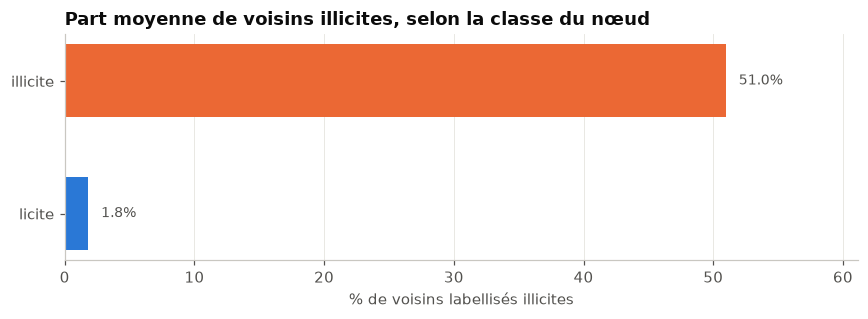

In [18]:
lab = df["label"].values
src = np.concatenate([edge_index[0], edge_index[1]])
dst = np.concatenate([edge_index[1], edge_index[0]])
mask = lab[dst] != -1
neigh = pd.DataFrame({"node": src[mask], "illicit_neigh": lab[dst[mask]] == 1})
frac = neigh.groupby("node")["illicit_neigh"].mean()
frac = frac[lab[frac.index] != -1]
frac_df = pd.DataFrame({"frac": frac.values, "classe": pd.Series(lab[frac.index]).map({1: "illicite", 0: "licite"})})

fig, ax = plt.subplots(figsize=(8, 3))
means = frac_df.groupby("classe")["frac"].mean().reindex(["licite", "illicite"])
bars = ax.barh(means.index, means.values * 100, color=[COLORS[k] for k in means.index], height=0.55)
for b, v in zip(bars, means.values):
    ax.text(v * 100 + 1, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center", color=INK2, fontsize=9)
ax.set_title("Part moyenne de voisins illicites, selon la classe du nœud")
ax.set_xlabel("% de voisins labellisés illicites"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, means.max() * 100 * 1.2)
plt.tight_layout(); plt.show()

### 4.5 Features les plus discriminantes
On classe les features par écart de moyenne standardisé entre licite et illicite, puis on compare leurs distributions.

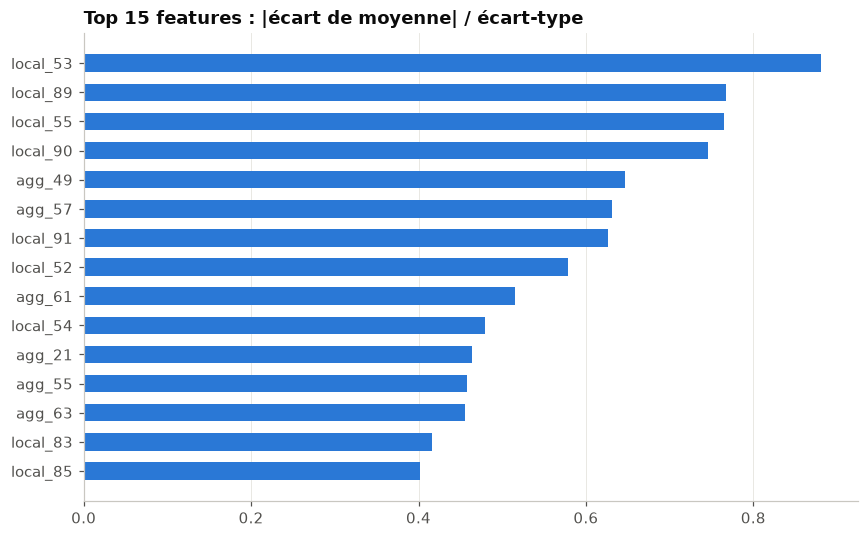

In [19]:
g = labeled.groupby("label")[feat_cols].mean()
effect = ((g.loc[1] - g.loc[0]) / labeled[feat_cols].std()).abs().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
top = effect.head(15)[::-1]
ax.barh(top.index, top.values, color=COLORS["licite"], height=0.6)
ax.set_title("Top 15 features : |écart de moyenne| / écart-type")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

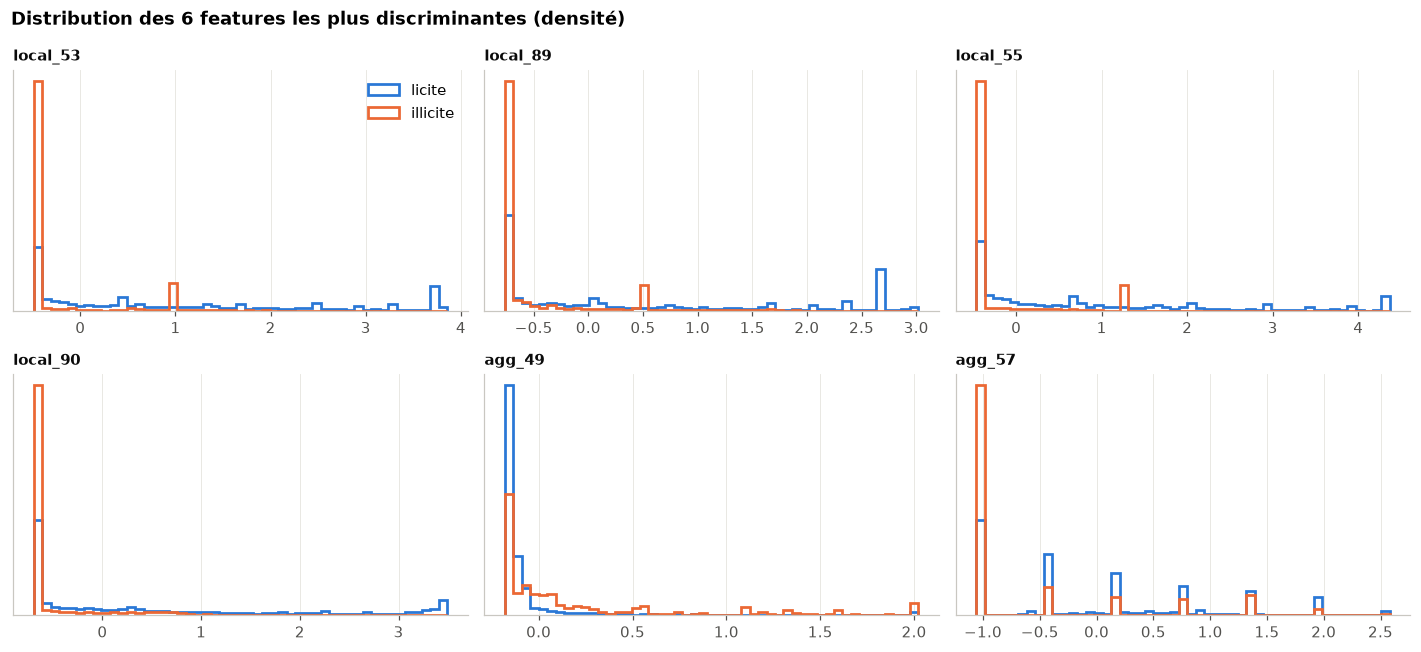

In [20]:
top6 = effect.head(6).index
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.flat, top6):
    lo, hi = labeled[col].quantile([0.01, 0.99])
    bins = np.linspace(lo, hi, 50)
    for cls, name in [(0, "licite"), (1, "illicite")]:
        ax.hist(labeled.loc[labeled["label"] == cls, col].clip(lo, hi), bins=bins, density=True,
                histtype="step", color=COLORS[name], linewidth=1.8, label=name)
    ax.set_title(col, fontsize=10); ax.set_yticks([])
axes.flat[0].legend()
fig.suptitle("Distribution des 6 features les plus discriminantes (densité)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 4.6 Corrélations entre features locales
De grands blocs très corrélés : beaucoup de features sont redondantes.

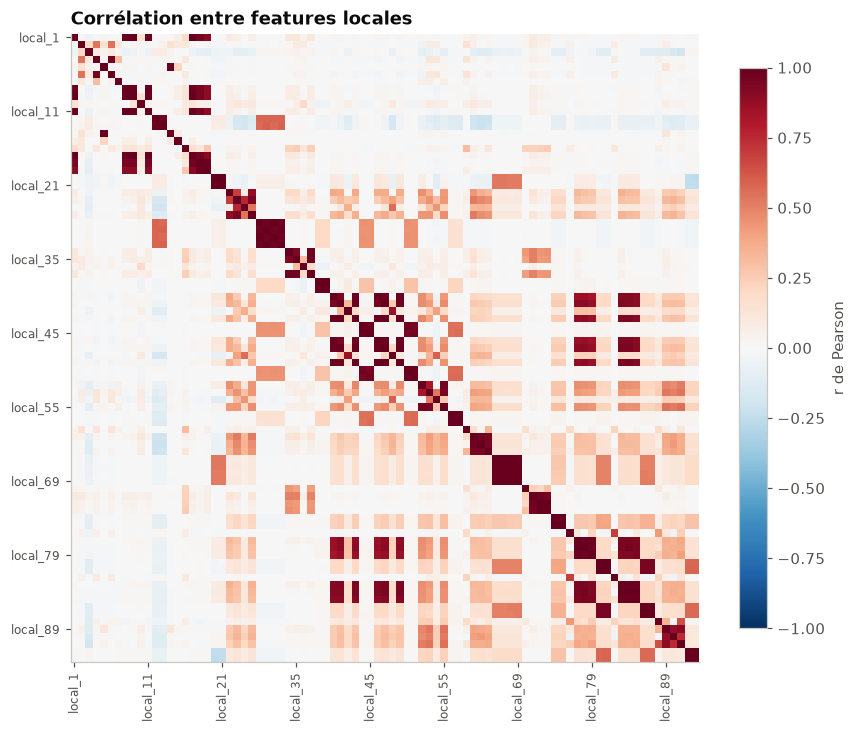

In [21]:
local_cols = [c for c in feat_cols if c.startswith("local_")]
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(np.corrcoef(df[local_cols].to_numpy(), rowvar=False), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_title("Corrélation entre features locales"); ax.grid(False)
ticks = range(0, len(local_cols), 10)
ax.set_xticks(ticks, [local_cols[i] for i in ticks], rotation=90, fontsize=8)
ax.set_yticks(ticks, [local_cols[i] for i in ticks], fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="r de Pearson")
plt.tight_layout(); plt.show()

### 4.7 Projection 2D (PCA)
Les transactions illicites sont-elles séparables à partir des seules features ?

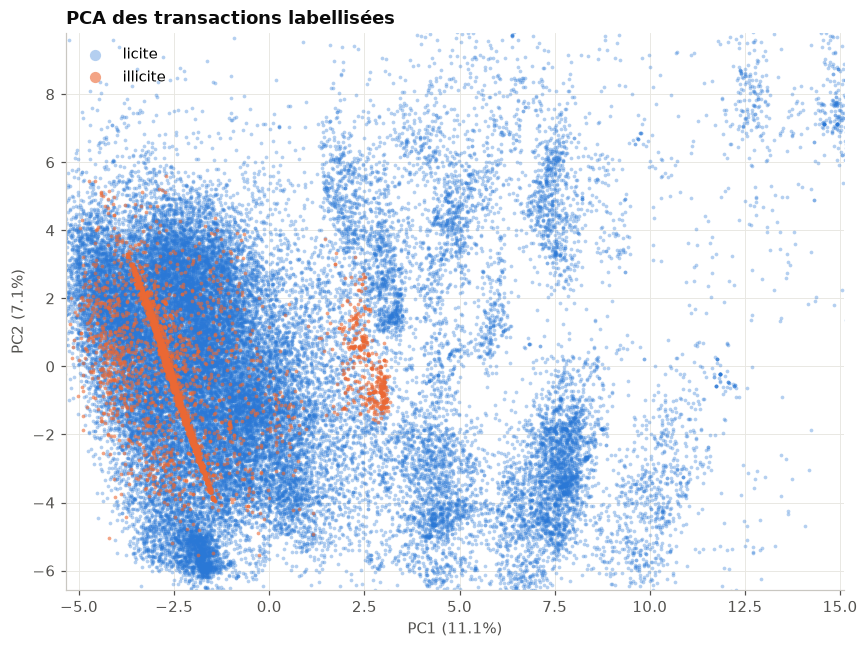

In [22]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(labeled[feat_cols])
pca = PCA(n_components=2, random_state=0)
Z = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
for cls, name in [(0, "licite"), (1, "illicite")]:
    m = labeled["label"].values == cls
    ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.35 if cls == 0 else 0.6, color=COLORS[name], label=name, linewidths=0)
ev = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({ev[0]:.1%})"); ax.set_ylabel(f"PC2 ({ev[1]:.1%})")
ax.set_title("PCA des transactions labellisées")
ax.legend(markerscale=3)
lo, hi = np.percentile(Z, [0.5, 99.5], axis=0)
ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
plt.tight_layout(); plt.show()

### 4.8 Voisinage d'une transaction illicite
Sous-graphe à 2 sauts autour d'une transaction illicite (couleur = classe).

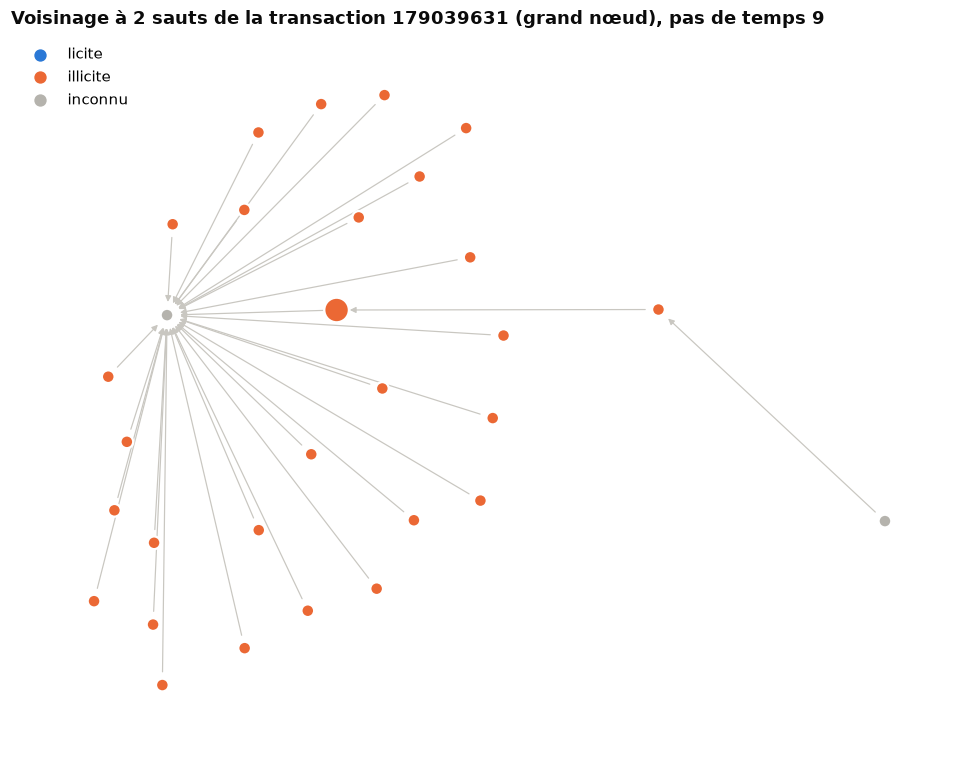

In [23]:
import networkx as nx

G = nx.DiGraph()
G.add_edges_from(zip(edge_index[0], edge_index[1]))

rng = np.random.default_rng(0)
illicit_nodes = np.where(lab == 1)[0]
# on choisit un nœud illicite dont le voisinage à 2 sauts a une taille lisible
for center in rng.permutation(illicit_nodes):
    if center not in G:
        continue
    sub_nodes = nx.ego_graph(G, center, radius=2, undirected=True).nodes
    if 25 <= len(sub_nodes) <= 80:
        break
H = G.subgraph(sub_nodes)

name_of = {1: "illicite", 0: "licite", -1: "inconnu"}
node_colors = [COLORS[name_of[lab[n]]] for n in H.nodes]
sizes = [260 if n == center else 70 for n in H.nodes]

fig, ax = plt.subplots(figsize=(9, 7))
pos = nx.spring_layout(H, seed=1, k=0.6)
nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#c9c7c1", arrowsize=8, width=0.8)
nx.draw_networkx_nodes(H, pos, ax=ax, node_color=node_colors, node_size=sizes, edgecolors="white", linewidths=1.5)
for name, c in COLORS.items():
    ax.scatter([], [], color=c, label=name, s=50)
ax.legend(loc="upper left"); ax.set_axis_off()
ax.set_title(f"Voisinage à 2 sauts de la transaction {df.loc[center, 'txId']} (grand nœud), pas de temps {df.loc[center, 'time_step']}")
plt.tight_layout(); plt.show()

## 5. Graphe PyTorch Geometric

**Split temporel** (comme Weber et al., 2019) : pas de temps 1 à 34 = train, 35 à 49 = test. Les nœuds inconnus restent dans le graphe (ils transmettent l'information) mais ne sont dans aucun masque.

Les features sont standardisées avec la moyenne et l'écart-type **du train uniquement**, pour ne pas faire fuir d'information du test.

In [24]:
TRAIN_END = 34

time_step = df["time_step"].to_numpy(copy=True)
y_np = df["label"].to_numpy(copy=True)
train_mask_np = (time_step <= TRAIN_END) & (y_np != -1)
test_mask_np = (time_step > TRAIN_END) & (y_np != -1)

scaler = StandardScaler().fit(df.loc[time_step <= TRAIN_END, feat_cols])
x_np = scaler.transform(df[feat_cols]).astype(np.float32)

data = Data(
    x=torch.from_numpy(x_np),
    edge_index=torch.from_numpy(edge_index).long(),
    y=torch.from_numpy(y_np).long(),
    time_step=torch.from_numpy(time_step).long(),
    train_mask=torch.from_numpy(train_mask_np),
    test_mask=torch.from_numpy(test_mask_np),
)
data

Data(x=[203769, 157], edge_index=[2, 234355], y=[203769], time_step=[203769], train_mask=[203769], test_mask=[203769])

In [25]:
print(f"nœuds : {data.num_nodes} | arêtes : {data.num_edges} | features : {data.num_node_features}")
print("graphe valide :", data.validate(raise_on_error=False))
for name, m in [("train", train_mask_np), ("test", test_mask_np)]:
    n, n_ill = m.sum(), (y_np[m] == 1).sum()
    print(f"{name:5s} : {n:6d} nœuds labellisés dont {n_ill:5d} illicites ({n_ill / n:.1%})")

nœuds : 203769 | arêtes : 234355 | features : 157
graphe valide : True
train :  29894 nœuds labellisés dont  3462 illicites (11.6%)
test  :  16670 nœuds labellisés dont  1083 illicites (6.5%)


## 6. Baseline : Random Forest (sans graphe)

Chaque transaction est classée **isolément**, à partir de ses seules features. Deux variantes :
- **features locales** : uniquement la transaction elle-même ;
- **toutes les features** : locales + agrégées (les 72 features agrégées résument déjà un peu le voisinage).

Hyperparamètres de Weber et al. : 50 arbres, 50 features max par split. La métrique principale est le F1 de la classe illicite.

In [26]:
local_feat_idx = [i for i, c in enumerate(feat_cols) if c.startswith("local_")]
X_train, y_train = x_np[train_mask_np], y_np[train_mask_np]
X_test, y_test = x_np[test_mask_np], y_np[test_mask_np]

def evaluate(name, y_true, y_pred):
    return {
        "modèle": name,
        "précision": precision_score(y_true, y_pred, pos_label=1),
        "rappel": recall_score(y_true, y_pred, pos_label=1),
        "F1": f1_score(y_true, y_pred, pos_label=1),
    }

results, rf_preds = [], {}
for name, cols in [("RF — features locales", local_feat_idx), ("RF — toutes les features", list(range(len(feat_cols))))]:
    rf = RandomForestClassifier(n_estimators=50, max_features=50, n_jobs=-1, random_state=42)
    rf.fit(X_train[:, cols], y_train)
    rf_preds[name] = rf.predict(X_test[:, cols])
    results.append(evaluate(name, y_test, rf_preds[name]))

rf_all = rf  # dernier modèle entraîné = toutes les features
results_df = pd.DataFrame(results).set_index("modèle")
results_df.round(3)

,précision,rappel,F1
modèle,,,
RF — features locales,0.839,0.708,0.768
RF — toutes les features,0.951,0.723,0.822


In [27]:
print(classification_report(y_test, rf_preds["RF — toutes les features"], target_names=["licite", "illicite"], digits=3))

              precision    recall  f1-score   support

      licite      0.981     0.997     0.989     15587
    illicite      0.951     0.723     0.822      1083

    accuracy                          0.980     16670
   macro avg      0.966     0.860     0.905     16670
weighted avg      0.979     0.980     0.978     16670



### F1 illicite par pas de temps (test)
Le modèle s'effondre à partir du pas 43, quand le marché du darknet ferme et que les comportements illicites changent.

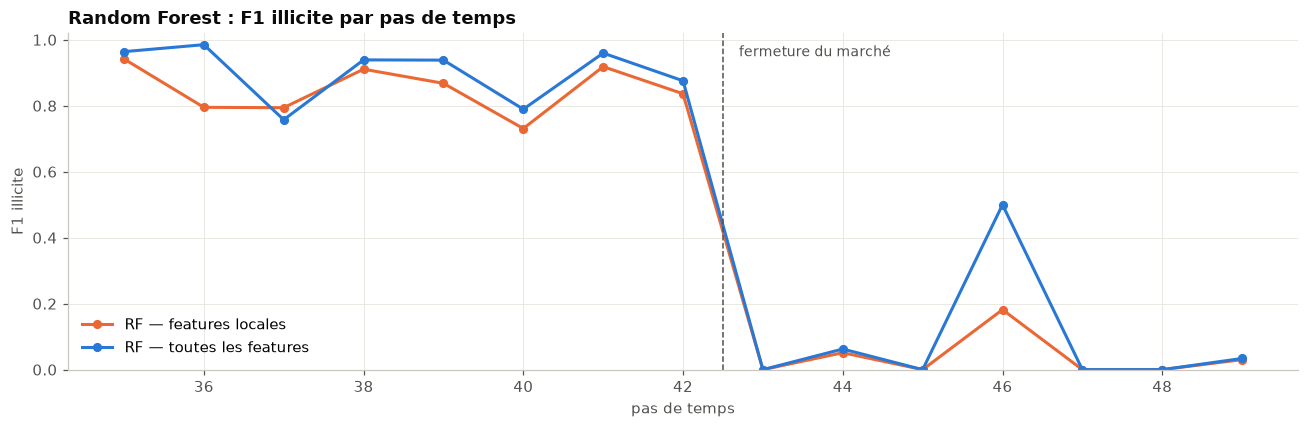

In [28]:
test_steps = time_step[test_mask_np]
fig, ax = plt.subplots(figsize=(12, 4))
for name, color in [("RF — features locales", COLORS["illicite"]), ("RF — toutes les features", COLORS["licite"])]:
    f1_per_step = [f1_score(y_test[test_steps == t], rf_preds[name][test_steps == t], pos_label=1, zero_division=0)
                   for t in sorted(np.unique(test_steps))]
    ax.plot(sorted(np.unique(test_steps)), f1_per_step, color=color, marker="o", markersize=5, label=name)
ax.axvline(42.5, color=INK2, ls="--", lw=1)
ax.text(42.7, 0.95, "fermeture du marché", color=INK2, fontsize=9)
ax.set_ylim(0, 1.02); ax.set_xlabel("pas de temps"); ax.set_ylabel("F1 illicite")
ax.set_title("Random Forest : F1 illicite par pas de temps")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

### Importance des features (RF toutes features)

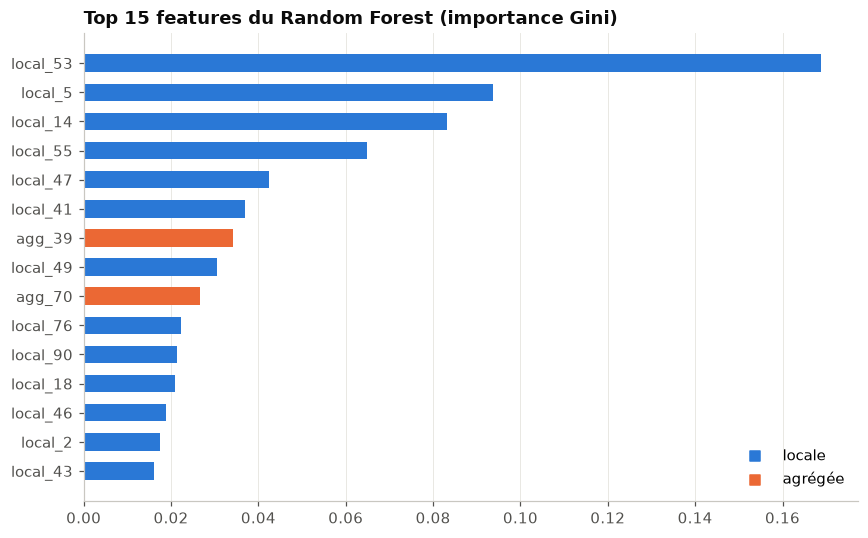

In [29]:
imp = pd.Series(rf_all.feature_importances_, index=feat_cols).sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values,
        color=[COLORS["licite"] if c.startswith("local_") else COLORS["illicite"] for c in imp.index], height=0.6)
ax.scatter([], [], color=COLORS["licite"], marker="s", label="locale")
ax.scatter([], [], color=COLORS["illicite"], marker="s", label="agrégée")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Top 15 features du Random Forest (importance Gini)")
plt.tight_layout(); plt.show()

## 7. Graph Neural Networks

**Validation.** Pour choisir l'epoch et le seuil de décision sans regarder le test, on met de côté **15 % des nœuds labellisés des pas 1 à 34** (tirage stratifié). Le test (pas 35 à 49) n'est utilisé qu'une seule fois, à la fin.

**Graphe non orienté.** Les arêtes sont rendues symétriques : un nœud reçoit l'information de ses prédécesseurs *et* de ses successeurs.

**Loss pondérée.** Poids de classe inversement proportionnels aux effectifs du train, pour compenser les ~11 % d'illicites.

In [30]:
import time
import torch_geometric.transforms as T
from torch_geometric.nn import GATConv
from sklearn.model_selection import train_test_split

torch.set_num_threads(max(1, torch.get_num_threads()))

# split train / validation à l'intérieur des pas 1-34
train_idx_all = np.where(train_mask_np)[0]
fit_idx, val_idx = train_test_split(train_idx_all, test_size=0.15, stratify=y_np[train_idx_all], random_state=0)
fit_mask = torch.zeros(data.num_nodes, dtype=torch.bool); fit_mask[fit_idx] = True
val_mask = torch.zeros(data.num_nodes, dtype=torch.bool); val_mask[val_idx] = True
test_mask = data.test_mask

# graphe non orienté + matrice d'adjacence creuse (plus rapide sur CPU)
gdata = T.ToSparseTensor(layout=torch.sparse_csr)(T.ToUndirected()(data.clone()))
X_t, ADJ, Y_t = gdata.x, gdata.adj_t, gdata.y

n = torch.bincount(Y_t[fit_mask], minlength=2).float()
CLASS_WEIGHTS = n.sum() / (2 * n)
print(f"fit : {fit_mask.sum().item()} | val : {val_mask.sum().item()} | test : {test_mask.sum().item()}")
print("poids de classe (licite, illicite) :", CLASS_WEIGHTS.numpy().round(2))

fit : 25409 | val : 4485 | test : 16670
poids de classe (licite, illicite) : [0.57 4.32]


C:\Users\Busin\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch_geometric\utils\sparse.py:276: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  adj = torch.sparse_csr_tensor(
C:\Users\Busin\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch_geometric\utils\sparse.py:276: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\SparseCsrTensorImpl.cpp:51.)
  adj = torch.spar

### 7.1 Modèles
Trois architectures à 2 couches (157 → 64 → 2) :
- **GCN** : moyenne pondérée des features des voisins (normalisée par les degrés) ;
- **GraphSAGE** : concatène ses propres features et la moyenne des voisins — le nœud garde « sa voix » ;
- **GAT** : 4 têtes d'attention, le modèle apprend quels voisins comptent le plus.

In [31]:
class GNN(torch.nn.Module):
    def __init__(self, kind, d_in, hidden=64, dropout=0.5):
        super().__init__()
        if kind == "GCN":
            self.conv1, self.conv2 = GCNConv(d_in, hidden, cached=True), GCNConv(hidden, 2, cached=True)
        elif kind == "GraphSAGE":
            self.conv1, self.conv2 = SAGEConv(d_in, hidden), SAGEConv(hidden, 2)
        elif kind == "GAT":
            self.conv1, self.conv2 = GATConv(d_in, hidden // 4, heads=4), GATConv(hidden, 2, heads=1)
        self.dropout = dropout

    def embed(self, x, adj):
        return F.relu(self.conv1(x, adj))

    def forward(self, x, adj):
        h = F.dropout(self.embed(x, adj), p=self.dropout, training=self.training)
        return self.conv2(h, adj)


def best_threshold(y_true, proba):
    """Seuil qui maximise le F1 illicite (choisi sur la validation)."""
    grid = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y_true, proba > t, zero_division=0) for t in grid]
    return grid[int(np.argmax(f1s))], max(f1s)


def train_gnn(kind, seed, epochs=200, lr=0.01, eval_every=5):
    torch.manual_seed(seed); np.random.seed(seed)
    model = GNN(kind, X_t.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    best = {"f1": -1}
    history = []
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        out = model(X_t, ADJ)
        loss = F.cross_entropy(out[fit_mask], Y_t[fit_mask], weight=CLASS_WEIGHTS)
        loss.backward(); opt.step()

        if epoch % eval_every == 0:
            model.eval()
            with torch.no_grad():
                proba = model(X_t, ADJ).softmax(1)[:, 1].numpy()
            val_f1 = f1_score(y_np[val_mask.numpy()], proba[val_mask.numpy()] > 0.5, zero_division=0)
            history.append((epoch, loss.item(), val_f1))
            if val_f1 > best["f1"]:
                best = {"f1": val_f1, "epoch": epoch, "state": {k: v.clone() for k, v in model.state_dict().items()}}

    model.load_state_dict(best["state"]); model.eval()
    with torch.no_grad():
        proba = model(X_t, ADJ).softmax(1)[:, 1].numpy()
    thr, _ = best_threshold(y_np[val_mask.numpy()], proba[val_mask.numpy()])
    print(f"{kind:9s} seed {seed} | meilleure epoch {best['epoch']:3d} | F1 val {best['f1']:.3f} | seuil {thr:.2f} | {time.time() - t0:.0f}s")
    return model, proba, thr, pd.DataFrame(history, columns=["epoch", "loss", "val_f1"])

### 7.2 Entraînement
GCN et GraphSAGE : 3 graines (on rapporte moyenne ± écart-type). GAT : 1 graine (≈ 3× plus lent sur CPU).

In [32]:
SEEDS = [0, 1, 2]
EPOCHS = 200
GNN_PLAN = [("GCN", SEEDS), ("GraphSAGE", SEEDS), ("GAT", SEEDS[:1])]
runs = {}   # (modèle, seed) -> (model, proba, seuil, historique)

if TRAIN_GNN or not GNN_CACHE.exists():
    for kind, seeds in GNN_PLAN:
        for seed in seeds:
            runs[(kind, seed)] = train_gnn(kind, seed, epochs=EPOCHS)
    torch.save({key: {"state": m.state_dict(), "proba": p, "thr": t, "history": h}
                for key, (m, p, t, h) in runs.items()}, GNN_CACHE)
    print("sauvegardé dans", GNN_CACHE)
else:
    cached = torch.load(GNN_CACHE, weights_only=False)
    for (kind, seed), r in cached.items():
        model = GNN(kind, X_t.shape[1]); model.load_state_dict(r["state"]); model.eval()
        runs[(kind, seed)] = (model, r["proba"], r["thr"], r["history"])
        print(f"{kind:9s} seed {seed} | chargé du cache | seuil {r['thr']:.2f}")

GCN       seed 0 | chargé du cache | seuil 0.83
GCN       seed 1 | chargé du cache | seuil 0.82
GCN       seed 2 | chargé du cache | seuil 0.75
GraphSAGE seed 0 | chargé du cache | seuil 0.74
GraphSAGE seed 1 | chargé du cache | seuil 0.83
GraphSAGE seed 2 | chargé du cache | seuil 0.77


GAT       seed 0 | chargé du cache | seuil 0.85


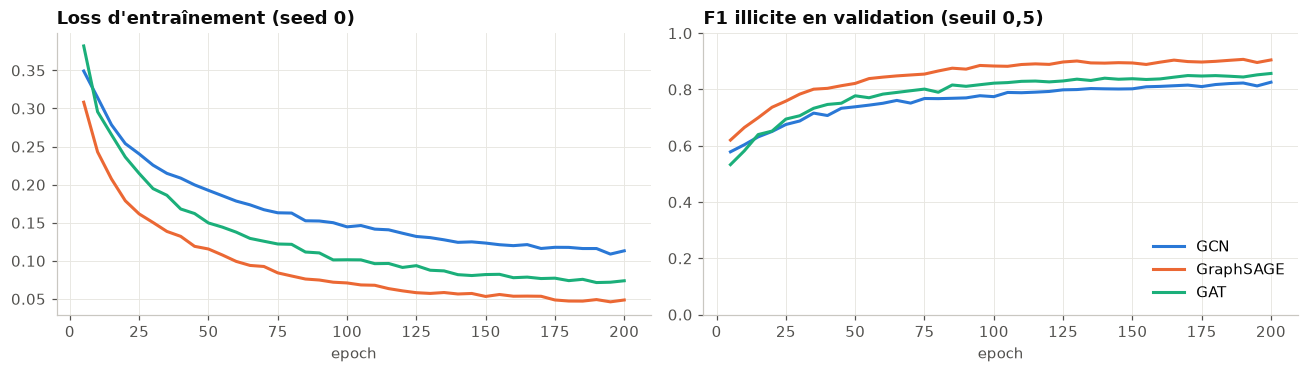

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for i, kind in enumerate(["GCN", "GraphSAGE", "GAT"]):
    h = runs[(kind, 0)][3]
    color = SERIES[i]
    axes[0].plot(h["epoch"], h["loss"], color=color, label=kind)
    axes[1].plot(h["epoch"], h["val_f1"], color=color, label=kind)
axes[0].set_title("Loss d'entraînement (seed 0)"); axes[0].set_xlabel("epoch")
axes[1].set_title("F1 illicite en validation (seuil 0,5)"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0, 1)
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 8. Combinaison : embeddings GraphSAGE → Random Forest
Piste du README : la couche cachée du GNN (64 dimensions, qui résume le voisinage) est ajoutée aux features d'origine, puis un Random Forest est entraîné dessus. Même protocole que la baseline (train = pas 1 à 34).

In [34]:
sage_model = runs[("GraphSAGE", 0)][0]
with torch.no_grad():
    emb = sage_model.embed(X_t, ADJ).numpy()
X_comb = np.hstack([x_np, emb])

## 9. Comparaison des modèles
Tous les modèles sont évalués sur le même test (pas 35 à 49). Les Random Forest sont aussi relancés avec 3 graines.

In [35]:
rows, test_preds = [], {}

def add_result(name, seed, y_pred):
    rows.append({"modèle": name, "seed": seed, **{k: v for k, v in evaluate(name, y_test, y_pred).items() if k != "modèle"}})
    test_preds.setdefault(name, y_pred)   # on garde la seed 0 pour les analyses

for seed in SEEDS:
    for name, X_tr, X_te in [
        ("RF — features locales", X_train[:, local_feat_idx], X_test[:, local_feat_idx]),
        ("RF — toutes les features", X_train, X_test),
        ("RF — features + embeddings GraphSAGE", X_comb[train_mask_np], X_comb[test_mask_np]),
    ]:
        rf = RandomForestClassifier(n_estimators=50, max_features=50, n_jobs=-1, random_state=seed).fit(X_tr, y_train)
        add_result(name, seed, rf.predict(X_te))

for (kind, seed), (_, proba, thr, _) in runs.items():
    add_result(kind, seed, (proba[test_mask_np] > thr).astype(int))

all_runs = pd.DataFrame(rows)
order = ["RF — features locales", "RF — toutes les features", "GCN", "GraphSAGE", "GAT", "RF — features + embeddings GraphSAGE"]
summary = all_runs.groupby("modèle")[["précision", "rappel", "F1"]].agg(["mean", "std"]).reindex(order)
summary["runs"] = all_runs.groupby("modèle").size().reindex(order)
summary.round(3)

précision        rappel            F1  \
                                          mean    std   mean    std   mean   
modèle                                                                       
RF — features locales                    0.855  0.016  0.707  0.003  0.774   
RF — toutes les features                 0.930  0.006  0.723  0.003  0.814   
GCN                                      0.774  0.045  0.443  0.023  0.563   
GraphSAGE                                0.736  0.058  0.564  0.044  0.638   
GAT                                      0.672    NaN  0.515    NaN  0.583   
RF — features + embeddings GraphSAGE     0.967  0.007  0.696  0.004  0.810   

                                            runs  
                                        std       
modèle                                            
RF — features locales                 0.004    3  
RF — toutes les features              0.001    3  
GCN                                   0.027    3  
GraphSAGE                             0.042    3  
GAT                                     NaN    1  
RF — features + embeddings GraphSAGE  0.001    3

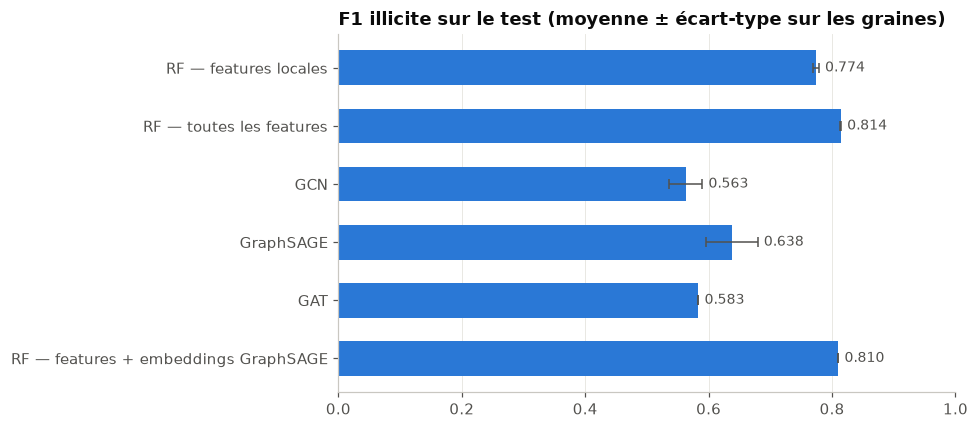

In [36]:
fig, ax = plt.subplots(figsize=(9, 4))
f1 = summary[("F1", "mean")][::-1]
err = summary[("F1", "std")][::-1].fillna(0)
ax.barh(f1.index, f1.values, xerr=err.values, color=COLORS["licite"], height=0.6,
        error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
for i, v in enumerate(f1.values):
    ax.text(v + err.values[i] + 0.01, i, f"{v:.3f}", va="center", color=INK2, fontsize=9)
ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
ax.set_title("F1 illicite sur le test (moyenne ± écart-type sur les graines)")
plt.tight_layout(); plt.show()

### F1 par pas de temps
Les GNN résistent-ils mieux au changement de comportement après la fermeture du marché (pas 43) ?

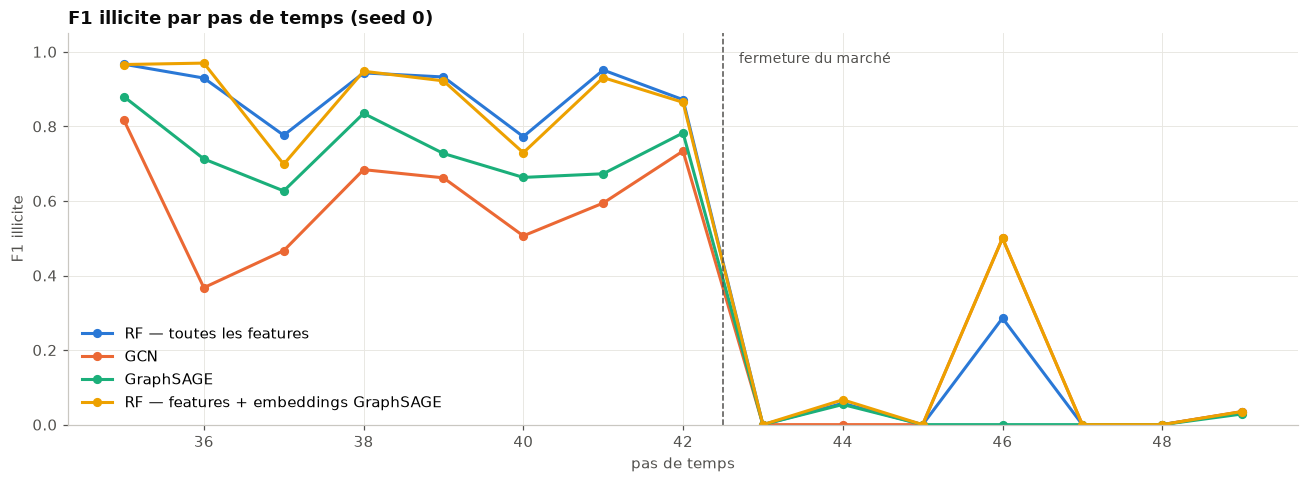

In [37]:
steps = sorted(np.unique(test_steps))
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, name in enumerate(["RF — toutes les features", "GCN", "GraphSAGE", "RF — features + embeddings GraphSAGE"]):
    f1_step = [f1_score(y_test[test_steps == t], test_preds[name][test_steps == t], zero_division=0) for t in steps]
    ax.plot(steps, f1_step, color=SERIES[i], marker="o", markersize=5, label=name)
ax.axvline(42.5, color=INK2, ls="--", lw=1)
ax.text(42.7, 0.97, "fermeture du marché", color=INK2, fontsize=9)
ax.set_ylim(0, 1.05); ax.set_xlabel("pas de temps"); ax.set_ylabel("F1 illicite")
ax.set_title("F1 illicite par pas de temps (seed 0)")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

### Où les modèles se trompent-ils ?
Illicites manqués (faux négatifs) avant / après la fermeture du marché, et fausses alertes.

In [38]:
err_rows = []
before = test_steps <= 42
for name in order:
    p = test_preds[name]
    err_rows.append({
        "modèle": name,
        "illicites manqués (pas 35-42)": int(((y_test == 1) & (p == 0) & before).sum()),
        "illicites manqués (pas 43-49)": int(((y_test == 1) & (p == 0) & ~before).sum()),
        "fausses alertes": int(((y_test == 0) & (p == 1)).sum()),
    })
print(f"illicites dans le test : {(y_test[before] == 1).sum()} (pas 35-42) + {(y_test[~before] == 1).sum()} (pas 43-49)")
pd.DataFrame(err_rows).set_index("modèle")

illicites dans le test : 914 (pas 35-42) + 169 (pas 43-49)


,illicites manqués (pas 35-42),illicites manqués (pas 43-49),fausses alertes
modèle,,,
RF — features locales,151,166,129
RF — toutes les features,135,166,55
GCN,413,167,150
GraphSAGE,250,167,215
GAT,359,166,272
RF — features + embeddings GraphSAGE,167,166,19


In [39]:
# F1 sur la période « stable » (avant la fermeture du marché)
stable = all_runs.copy()
stable_f1 = []
for name in order:
    p = test_preds[name]
    stable_f1.append({"modèle": name,
                      "F1 pas 35-42": f1_score(y_test[before], p[before]),
                      "F1 pas 43-49": f1_score(y_test[~before], p[~before], zero_division=0)})
pd.DataFrame(stable_f1).set_index("modèle").round(3)

,F1 pas 35-42,F1 pas 43-49
modèle,,
RF — features locales,0.869,0.027
RF — toutes les features,0.904,0.030
GCN,0.675,0.016
GraphSAGE,0.769,0.017
GAT,0.652,0.029
RF — features + embeddings GraphSAGE,0.894,0.033


## 10. Tuning du meilleur modèle : Random Forest

**Validation temporelle.** Les hyperparamètres sont choisis sur deux plis « fenêtre croissante », sans jamais toucher au test :

| Pli | Train | Validation |
|---|---|---|
| 1 | pas 1–24 | pas 25–29 |
| 2 | pas 1–29 | pas 30–34 |

Score = F1 illicite moyen sur les deux plis. Recherche aléatoire sur 30 configurations, plus la configuration de départ (Weber et al.).

In [40]:
from sklearn.model_selection import ParameterSampler

FOLDS = [(24, (25, 29)), (29, (30, 34))]
lab_mask = y_np != -1

def fold_masks(train_end, val_range):
    tr = lab_mask & (time_step <= train_end)
    va = lab_mask & (time_step >= val_range[0]) & (time_step <= val_range[1])
    return tr, va

search_space = {
    "n_estimators": [100, 200, 300],
    "max_features": ["sqrt", "log2", 0.1, 0.2, 50],
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced_subsample"],
}
N_ITER = 30
baseline_params = {"n_estimators": 50, "max_features": 50, "max_depth": None, "min_samples_leaf": 1, "class_weight": None}
configs = [baseline_params] + list(ParameterSampler(search_space, n_iter=N_ITER, random_state=0))

tuning_rows = []
t0 = time.time()
if not RUN_TUNING and TUNING_CACHE.exists():
    tuning_rows, configs = pd.read_pickle(TUNING_CACHE), []
    print("chargé du cache :", TUNING_CACHE)
for i, params in enumerate(configs):
    f1s = []
    for train_end, val_range in FOLDS:
        tr, va = fold_masks(train_end, val_range)
        rf = RandomForestClassifier(**params, n_jobs=-1, random_state=0).fit(x_np[tr], y_np[tr])
        f1s.append(f1_score(y_np[va], rf.predict(x_np[va])))
    tuning_rows.append({**params, "F1 pli 1": f1s[0], "F1 pli 2": f1s[1], "F1 val": np.mean(f1s)})
if configs:
    pd.to_pickle(tuning_rows, TUNING_CACHE)
    print(f"{len(configs)} configurations évaluées en {time.time() - t0:.0f}s")

tuning = pd.DataFrame(tuning_rows).sort_values("F1 val", ascending=False).reset_index(drop=True)
tuning.head(10).round(3)

chargé du cache : cache\rf_tuning.pkl


,n_estimators,max_features,max_depth,min_samples_leaf,class_weight,F1 pli 1,F1 pli 2,F1 val
0,200,0.2,15.0,5,balanced_subsample,0.952,0.969,0.961
1,200,0.1,20.0,2,NaN,0.950,0.971,0.961
2,200,sqrt,NaN,1,NaN,0.952,0.968,0.960
3,200,50,NaN,5,balanced_subsample,0.950,0.968,0.959
4,300,0.1,15.0,2,NaN,0.948,0.970,0.959
5,200,log2,NaN,1,NaN,0.948,0.969,0.958
6,100,0.2,15.0,2,balanced_subsample,0.945,0.969,0.957
7,100,0.1,NaN,2,NaN,0.946,0.967,0.957
8,300,sqrt,NaN,2,balanced_subsample,0.947,0.965,0.956
9,300,sqrt,20.0,2,balanced_subsample,0.945,0.966,0.955


### Influence de chaque hyperparamètre
F1 de validation de chaque configuration, regroupé par valeur de l'hyperparamètre.

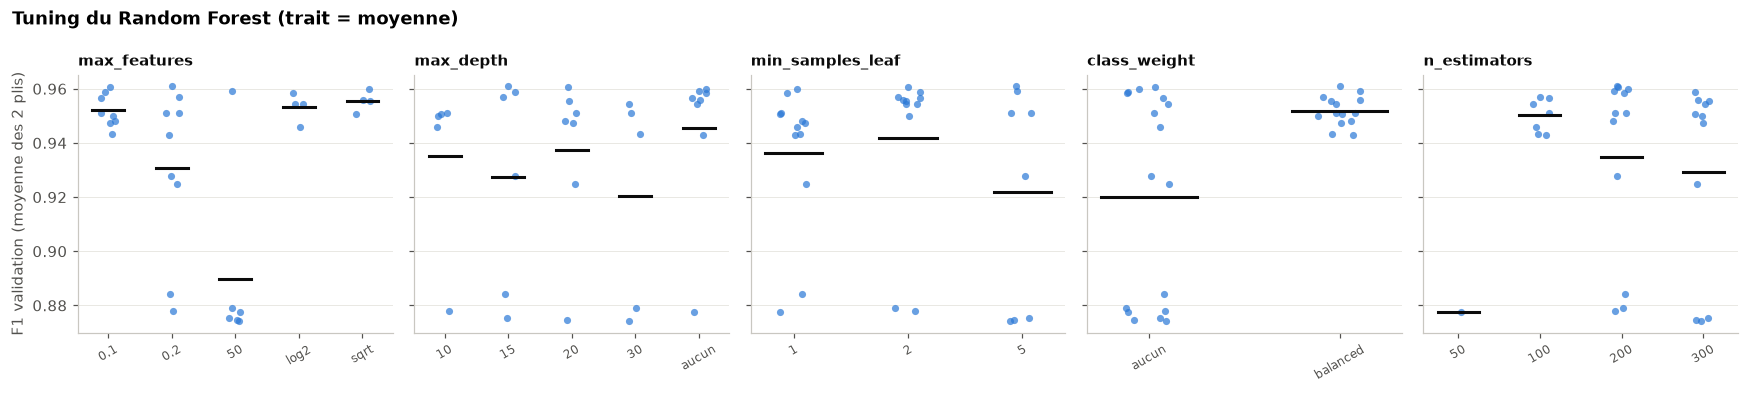

In [41]:
hp_names = ["max_features", "max_depth", "min_samples_leaf", "class_weight", "n_estimators"]
fig, axes = plt.subplots(1, len(hp_names), figsize=(16, 3.6), sharey=True)
for ax, hp in zip(axes, hp_names):
    vals = tuning[hp].map(lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(int(v)) if isinstance(v, float) and v.is_integer() else str(v)).replace({"None": "aucun", "balanced_subsample": "balanced"})
    cats = sorted(vals.unique(), key=lambda v: (not v.replace(".", "").isdigit(), float(v) if v.replace(".", "").isdigit() else 0, v))
    for j, cat in enumerate(cats):
        pts = tuning.loc[vals == cat, "F1 val"]
        ax.scatter(np.full(len(pts), j) + np.random.default_rng(j).uniform(-0.12, 0.12, len(pts)), pts,
                   s=22, color=COLORS["licite"], alpha=0.7, linewidths=0)
        ax.plot([j - 0.25, j + 0.25], [pts.mean()] * 2, color=INK, lw=2)
    ax.set_xticks(range(len(cats)), cats, fontsize=8, rotation=30)
    ax.set_title(hp, fontsize=10); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("F1 validation (moyenne des 2 plis)")
fig.suptitle("Tuning du Random Forest (trait = moyenne)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### Seuil de décision
Le seuil par défaut (0,5) n'est pas forcément optimal. On le choisit sur les probabilités des deux plis de validation, avec la meilleure configuration.

meilleure configuration : {'n_estimators': 200, 'max_features': 0.2, 'max_depth': 15, 'min_samples_leaf': 5, 'class_weight': 'balanced_subsample'}


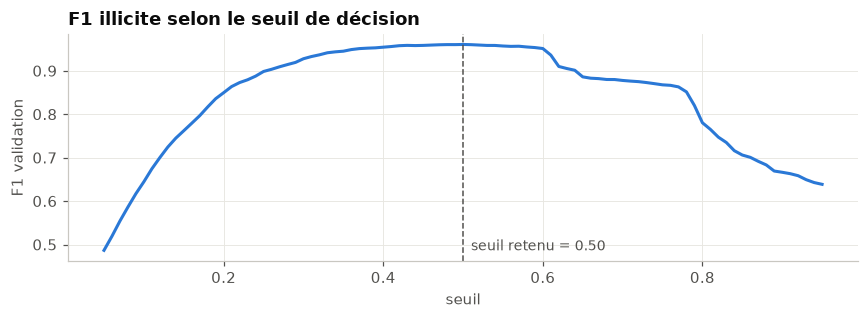

F1 validation : 0.960 (seuil 0,5) -> 0.961 (seuil 0.50)


In [42]:
best_params = {k: (None if pd.isna(v) else v) for k, v in tuning.loc[0, list(search_space)].items()}
for k in ["n_estimators", "max_depth", "min_samples_leaf"]:
    if best_params[k] is not None:
        best_params[k] = int(best_params[k])
print("meilleure configuration :", best_params)

val_true, val_proba = [], []
for train_end, val_range in FOLDS:
    tr, va = fold_masks(train_end, val_range)
    rf = RandomForestClassifier(**best_params, n_jobs=-1, random_state=0).fit(x_np[tr], y_np[tr])
    val_true.append(y_np[va]); val_proba.append(rf.predict_proba(x_np[va])[:, 1])
val_true, val_proba = np.concatenate(val_true), np.concatenate(val_proba)

grid = np.linspace(0.05, 0.95, 91)
f1_grid = np.array([f1_score(val_true, val_proba > t, zero_division=0) for t in grid])
best_thr = grid[f1_grid.argmax()]

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(grid, f1_grid, color=COLORS["licite"])
ax.axvline(best_thr, color=INK2, ls="--", lw=1)
ax.text(best_thr + 0.01, f1_grid.min(), f"seuil retenu = {best_thr:.2f}", color=INK2, fontsize=9)
ax.set_xlabel("seuil"); ax.set_ylabel("F1 validation"); ax.set_title("F1 illicite selon le seuil de décision")
plt.tight_layout(); plt.show()
print(f"F1 validation : {f1_grid[grid.searchsorted(0.5)]:.3f} (seuil 0,5) -> {f1_grid.max():.3f} (seuil {best_thr:.2f})")

### Évaluation finale sur le test
Le modèle retenu est réentraîné sur les pas 1–34, puis évalué **une seule fois** sur le test (3 graines).

In [43]:
final_rows, tuned_pred = [], None
for seed in SEEDS:
    rf_tuned = RandomForestClassifier(**best_params, n_jobs=-1, random_state=seed).fit(X_train, y_train)
    proba = rf_tuned.predict_proba(X_test)[:, 1]
    thresholds = [("seuil 0,5", 0.5)] + ([] if np.isclose(best_thr, 0.5) else [(f"seuil {best_thr:.2f}", best_thr)])
    for label, thr in thresholds:
        pred = (proba > thr).astype(int)
        final_rows.append({"modèle": f"RF tuné ({label})", "seed": seed,
                           **{k: v for k, v in evaluate("", y_test, pred).items() if k != "modèle"}})
        if seed == 0 and np.isclose(thr, best_thr):
            tuned_pred = pred

baseline = all_runs[all_runs["modèle"] == "RF — toutes les features"]
final = pd.concat([baseline, pd.DataFrame(final_rows)])
final_summary = final.groupby("modèle", sort=False)[["précision", "rappel", "F1"]].agg(["mean", "std"])
final_summary.round(3)

précision        rappel            F1       
                              mean    std   mean    std   mean    std
modèle                                                               
RF — toutes les features     0.930  0.006  0.723  0.003  0.814  0.001
RF tuné (seuil 0,5)          0.811  0.012  0.724  0.001  0.765  0.006

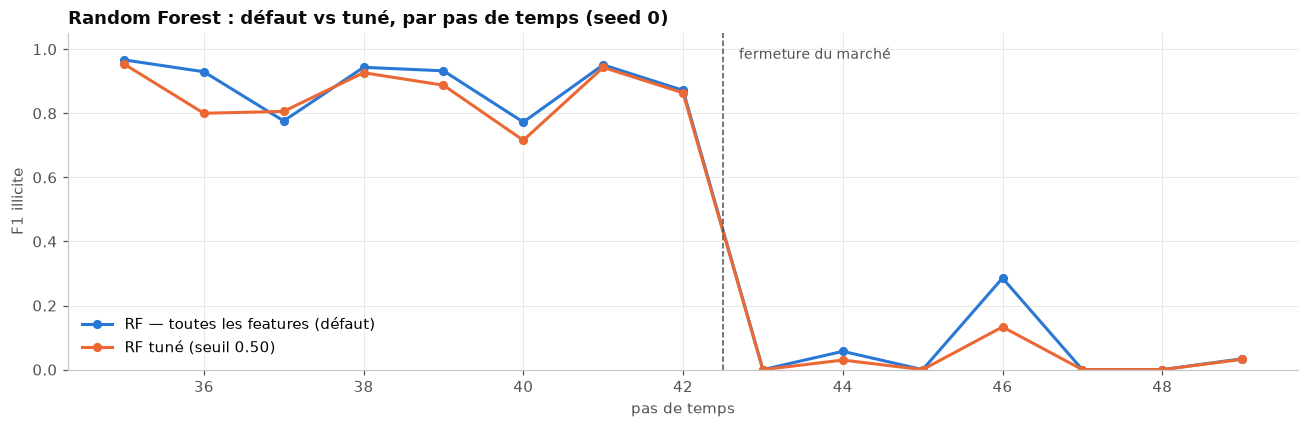

F1 pas 35-42 : 0.881 | F1 pas 43-49 : 0.023
illicites manqués (35-42 / 43-49) : 132 / 166 | fausses alertes : 167


In [44]:
steps = sorted(np.unique(test_steps))
fig, ax = plt.subplots(figsize=(12, 4))
for i, (name, pred) in enumerate([("RF — toutes les features (défaut)", test_preds["RF — toutes les features"]),
                                  (f"RF tuné (seuil {best_thr:.2f})", tuned_pred)]):
    f1_step = [f1_score(y_test[test_steps == t], pred[test_steps == t], zero_division=0) for t in steps]
    ax.plot(steps, f1_step, color=SERIES[i], marker="o", markersize=5, label=name)
ax.axvline(42.5, color=INK2, ls="--", lw=1)
ax.text(42.7, 0.97, "fermeture du marché", color=INK2, fontsize=9)
ax.set_ylim(0, 1.05); ax.set_xlabel("pas de temps"); ax.set_ylabel("F1 illicite")
ax.set_title("Random Forest : défaut vs tuné, par pas de temps (seed 0)")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

p = tuned_pred
print("F1 pas 35-42 :", round(f1_score(y_test[before], p[before]), 3),
      "| F1 pas 43-49 :", round(f1_score(y_test[~before], p[~before], zero_division=0), 3))
print("illicites manqués (35-42 / 43-49) :", int(((y_test == 1) & (p == 0) & before).sum()), "/",
      int(((y_test == 1) & (p == 0) & ~before).sum()), "| fausses alertes :", int(((y_test == 0) & (p == 1)).sum()))